## Early Detection of Diabetes Risk: A Predictive Analysis

### Introduction

Diabetes, a chronic metabolic disorder, has emerged as a significant global health concern, affecting millions of individuals worldwide. Early detection and intervention play a pivotal role in mitigating the complications associated with diabetes, emphasizing the need for reliable predictive models. In this context, we present a comprehensive analysis aimed at identifying statistically significant features associated with diabetes and constructing a robust classification model for early-stage risk assessment.

The dataset under scrutiny encompasses a diverse set of attributes, ranging from demographic factors such as age and gender to specific symptoms and medical indicators. These include polyuria, polydipsia, sudden weight loss, weakness, polyphagia, genital thrush, visual blurring, itching, irritability, delayed healing, partial paresis, muscle stiffness, alopecia, and obesity. The dataset classifies individuals into two categories: positive and negative for diabetes, providing a binary outcome for our analysis.

The primary objective of this project is to uncover the intricate relationships between these features and the likelihood of diabetes. Through rigorous statistical analysis, we aim to discern which attributes exhibit significant associations with diabetes, thereby providing valuable insights for clinicians and researchers alike. Subsequently, we intend to leverage these identified features to construct a classification model capable of predicting an individual's risk for diabetes based on their unique set of characteristics.

The implications of this research extend beyond the realm of academia, offering a practical and valuable resource for healthcare professionals. The predictive model developed from this dataset has the potential to enhance early intervention strategies, enabling healthcare providers to identify individuals at risk of diabetes at an earlier stage. By fostering a better understanding of the complex interplay between symptoms and diabetes onset, this analysis contributes to the ongoing efforts to improve public health outcomes and reduce the burden of this prevalent metabolic disorder.

### Import Essential Libraries

In [9]:
# import essential libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

### Load the Dataset

In [10]:
# load the dataset
data = pd.read_csv('data\diabetes_data_upload.csv')

# check the dimension of the dataset
print('Dimension of the dataset: ', data.shape)

# check the attributes in the dataset
print('Attributes in the dataset: ', data.columns.values)

# view the first 5 rows of the dataset
data.head()

<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
C:\Users\shive\AppData\Local\Temp\ipykernel_38188\2571405158.py:2: SyntaxWarning: invalid escape sequence '\d'
  data = pd.read_csv('data\diabetes_data_upload.csv')


Dimension of the dataset:  (520, 17)
Attributes in the dataset:  ['Age' 'Gender' 'Polyuria' 'Polydipsia' 'sudden weight loss' 'weakness'
 'Polyphagia' 'Genital thrush' 'visual blurring' 'Itching' 'Irritability'
 'delayed healing' 'partial paresis' 'muscle stiffness' 'Alopecia'
 'Obesity' 'class']


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


### Attributes Description

- Age (1-20 to 65): Age range of the individuals.
- Sex (1. Male, 2. Female): Gender information.
- Polyuria (1. Yes, 2. No): Presence of excessive urination.
- Polydipsia (1. Yes, 2. No): Excessive thirst.
- sudden weight loss (1. Yes, 2. No): Abrupt weight loss.
- weakness (1. Yes, 2. No): Generalized weakness.
- Polyphagia (1. Yes, 2. No): Excessive hunger.
- Genital Thrush (1. Yes, 2. No): Presence of genital thrush.
- visual blurring (1. Yes, 2. No): Blurring of vision.
- Itching (1. Yes, 2. No): Presence of itching.
- Irritability (1. Yes, 2. No): Display of irritability.
- delayed healing (1. Yes, 2. No): Delayed wound healing.
- partial paresis (1. Yes, 2. No): Partial loss of voluntary movement.
- muscle stiffness (1. Yes, 2. No): Presence of muscle stiffness.
- Alopecia (1. Yes, 2. No): Hair loss.
- Obesity (1. Yes, 2. No): Presence of obesity.
- class (1. Positive, 2. Negative): Diabetes classification.

In [11]:
# top level overview of the dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 520 non-null    int64 
 1   Gender              520 non-null    object
 2   Polyuria            520 non-null    object
 3   Polydipsia          520 non-null    object
 4   sudden weight loss  520 non-null    object
 5   weakness            520 non-null    object
 6   Polyphagia          520 non-null    object
 7   Genital thrush      520 non-null    object
 8   visual blurring     520 non-null    object
 9   Itching             520 non-null    object
 10  Irritability        520 non-null    object
 11  delayed healing     520 non-null    object
 12  partial paresis     520 non-null    object
 13  muscle stiffness    520 non-null    object
 14  Alopecia            520 non-null    object
 15  Obesity             520 non-null    object
 16  class               520 no

### Exploratory Data Analysis (EDA)

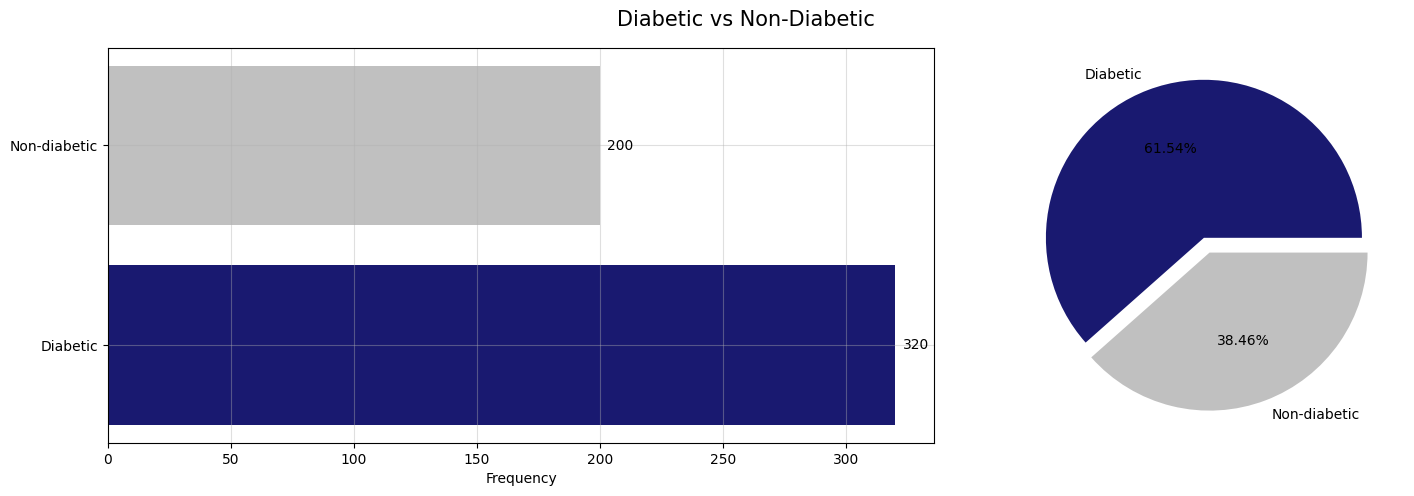

In [12]:
# distribution of diabetic and non-diabetic samples
samples = data['class'].value_counts()
colors = ['midnightblue','silver']

figure, axes = plt.subplots(1,2, figsize=(15,5), gridspec_kw={'width_ratios':[1.5,1]})
axes[0].barh(y=samples.index, width=samples.values, color=colors)
axes[0].set_xlabel('Frequency')
axes[0].set_yticks(['Negative','Positive'],['Non-diabetic','Diabetic'])
axes[0].grid(alpha=0.4)

for index, values in enumerate(samples):
    axes[0].text(values+3, index, str(values), va='center')
    
axes[1].pie(samples.values, labels=['Diabetic','Non-diabetic'], autopct='%.2f%%', explode=([0.05]*len(samples.index)), colors=colors)
figure.suptitle('Diabetic vs Non-Diabetic', fontsize=15)
plt.tight_layout(pad=1)
plt.show()

In [13]:
from scipy.stats import chi2_contingency

def chi2test(feature):
    # visualization
    plt.figure(figsize=(12,5))
    ax = sns.countplot(data=data, x=data[feature], hue=data['class'], palette=colors)
    ax.legend(['Diabetic','Non-diabetic'], loc='upper right', bbox_to_anchor=(1.2, 1))
    plt.title(f'Diabetic vs Non-Diabetic by {feature}', fontsize=15)
    plt.grid(alpha=0.4)
    plt.show()

    # display the contingency table (observed value)
    contingency_table = pd.crosstab(data[feature],data['class'])
    contingency_table.columns = ['Diabetic','Non-diabetic']
    print('Observed value:')
    display(contingency_table)

    # perform Chi-square test
    res = chi2_contingency(contingency_table)
    test_stat = round(res[0], 4)
    pvalue = round(res[1], 4)
    expected_frequency = res[3]

    print('Expected frequency:')
    display(pd.DataFrame(expected_frequency, index=contingency_table.index, columns=contingency_table.columns))

    print('Test statistics: ', test_stat)
    print('Test p-value: ', pvalue)

    alpha = 0.05
    if pvalue < alpha:
        print(f'Reject null hypothesis. There is a statistically significant association between {feature} and the likelihood of diabetes in the analyzed data.')
    else:
        print(f'Failed to reject null hypothesis. Lack of evidence to conclude a statistically significant association between {feature} and the likelihood of diabetes in the analyzed data.')

#### Question 1 | Is there a statistically significant association between gender and the likelihood of diabetes?

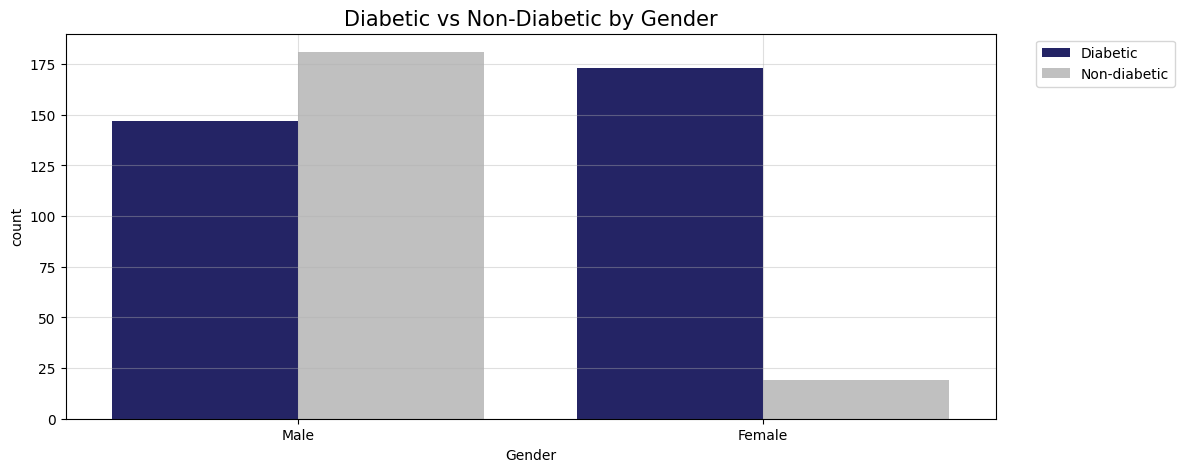

Observed value:


,Diabetic,Non-diabetic
Gender,,
Female,19,173
Male,181,147


Expected frequency:


,Diabetic,Non-diabetic
Gender,,
Female,73.846154,118.153846
Male,126.153846,201.846154


Test statistics:  103.0369
Test p-value:  0.0
Reject null hypothesis. There is a statistically significant association between Gender and the likelihood of diabetes in the analyzed data.


In [14]:
chi2test('Gender')

#### Question 2 | Does the presence of polyuria exhibit a statistically significant association with the likelihood of diabetes?

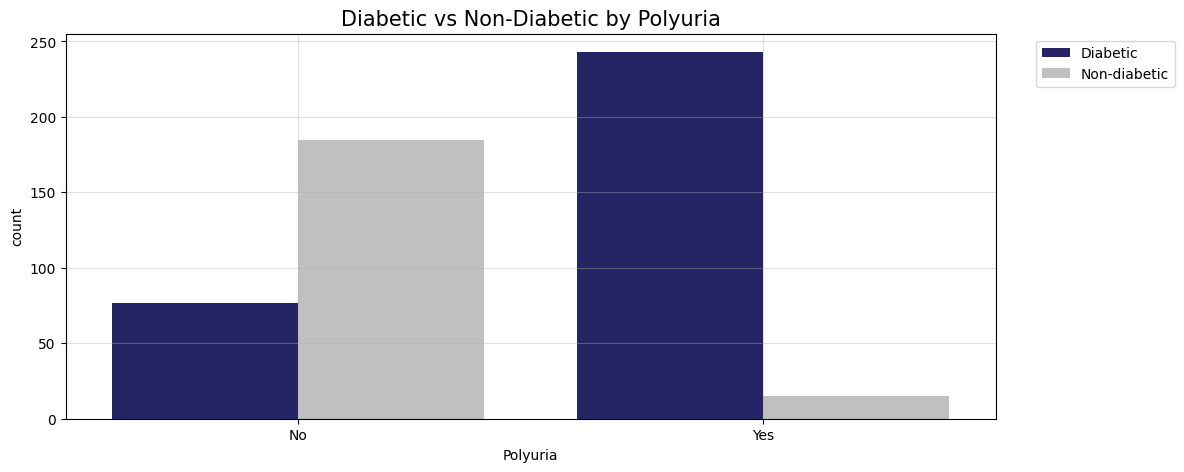

Observed value:


,Diabetic,Non-diabetic
Polyuria,,
No,185,77
Yes,15,243


Expected frequency:


,Diabetic,Non-diabetic
Polyuria,,
No,100.769231,161.230769
Yes,99.230769,158.769231


Test statistics:  227.8658
Test p-value:  0.0
Reject null hypothesis. There is a statistically significant association between Polyuria and the likelihood of diabetes in the analyzed data.


In [15]:
chi2test('Polyuria')

#### Question 3 | Does the presence of polydipsia exhibit a statistically significant association with the likelihood of diabetes?

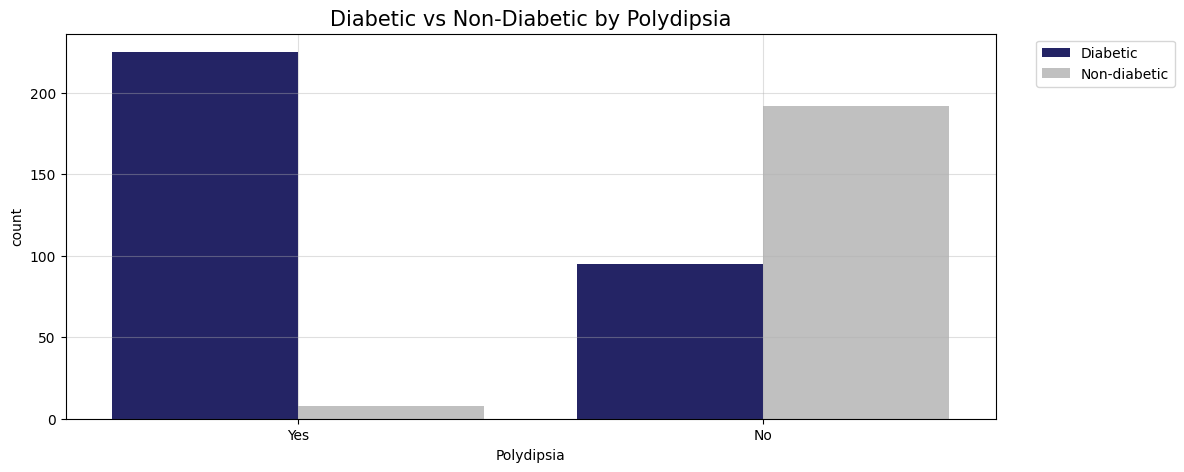

Observed value:


,Diabetic,Non-diabetic
Polydipsia,,
No,192,95
Yes,8,225


Expected frequency:


,Diabetic,Non-diabetic
Polydipsia,,
No,110.384615,176.615385
Yes,89.615385,143.384615


Test statistics:  216.1716
Test p-value:  0.0
Reject null hypothesis. There is a statistically significant association between Polydipsia and the likelihood of diabetes in the analyzed data.


In [16]:
chi2test('Polydipsia')

#### Question 4 | Is there a statistically significant association between the presence of sudden weight loss and the likelihood of diabetes?

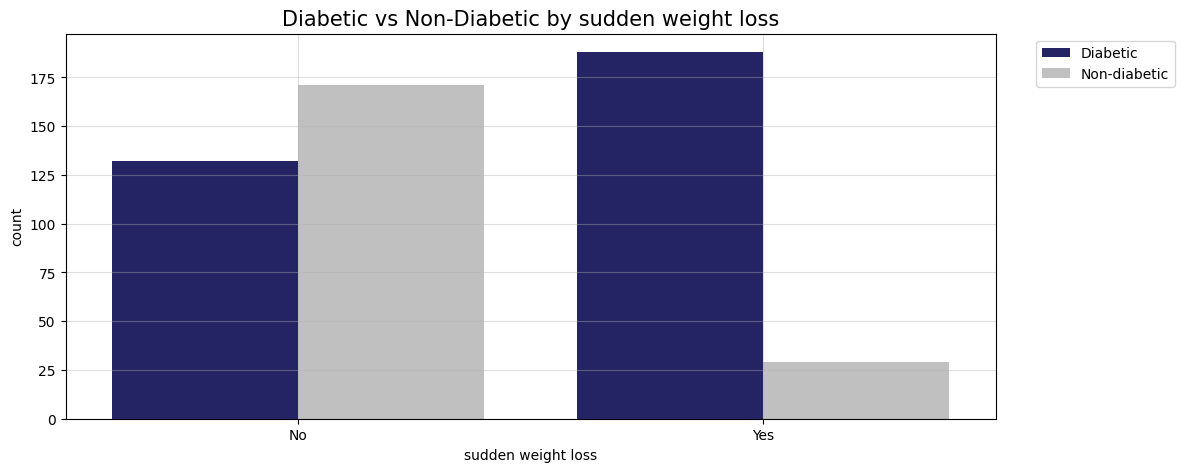

Observed value:


,Diabetic,Non-diabetic
sudden weight loss,,
No,171,132
Yes,29,188


Expected frequency:


,Diabetic,Non-diabetic
sudden weight loss,,
No,116.538462,186.461538
Yes,83.461538,133.538462


Test statistics:  97.2963
Test p-value:  0.0
Reject null hypothesis. There is a statistically significant association between sudden weight loss and the likelihood of diabetes in the analyzed data.


In [17]:
chi2test('sudden weight loss')

#### Question 5 | Does the presence of weakness exhibit a statistically significant association with the likelihood of diabetes? 

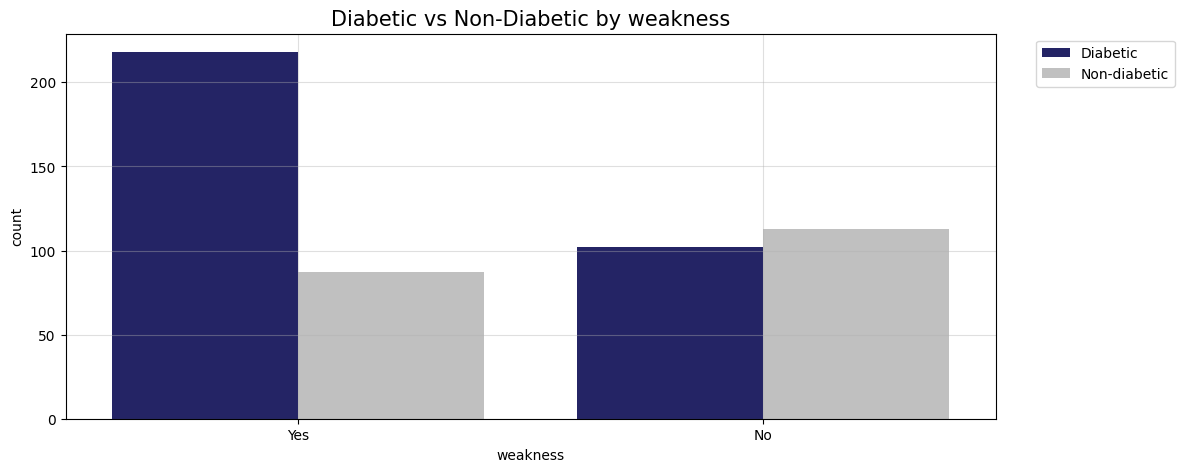

Observed value:


,Diabetic,Non-diabetic
weakness,,
No,113,102
Yes,87,218


Expected frequency:


,Diabetic,Non-diabetic
weakness,,
No,82.692308,132.307692
Yes,117.307692,187.692308


Test statistics:  29.7679
Test p-value:  0.0
Reject null hypothesis. There is a statistically significant association between weakness and the likelihood of diabetes in the analyzed data.


In [18]:
chi2test('weakness')

#### Question 6 | Is there a statistically significant association between the presence of polyphagia and the likelihood of diabetes?

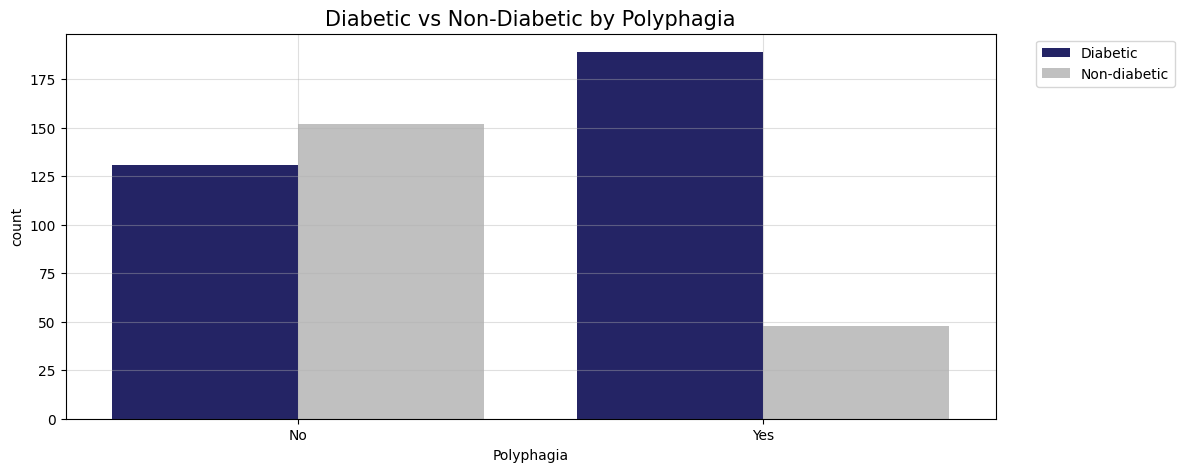

Observed value:


,Diabetic,Non-diabetic
Polyphagia,,
No,152,131
Yes,48,189


Expected frequency:


,Diabetic,Non-diabetic
Polyphagia,,
No,108.846154,174.153846
Yes,91.153846,145.846154


Test statistics:  59.5953
Test p-value:  0.0
Reject null hypothesis. There is a statistically significant association between Polyphagia and the likelihood of diabetes in the analyzed data.


In [19]:
chi2test('Polyphagia')

#### Question 7 | Is there a statistically significant association between the presence of genital thrush and the likelihood of diabetes?

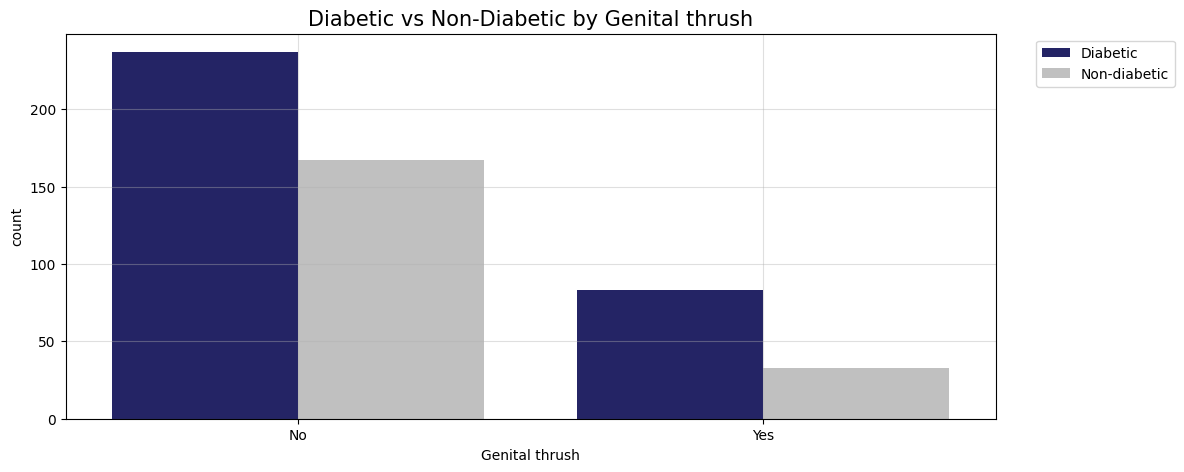

Observed value:


,Diabetic,Non-diabetic
Genital thrush,,
No,167,237
Yes,33,83


Expected frequency:


,Diabetic,Non-diabetic
Genital thrush,,
No,155.384615,248.615385
Yes,44.615385,71.384615


Test statistics:  5.7921
Test p-value:  0.0161
Reject null hypothesis. There is a statistically significant association between Genital thrush and the likelihood of diabetes in the analyzed data.


In [20]:
chi2test('Genital thrush')

#### Question 8 | Is there a statistically significant association between the presence of visual blurring and the likelihood of diabetes?

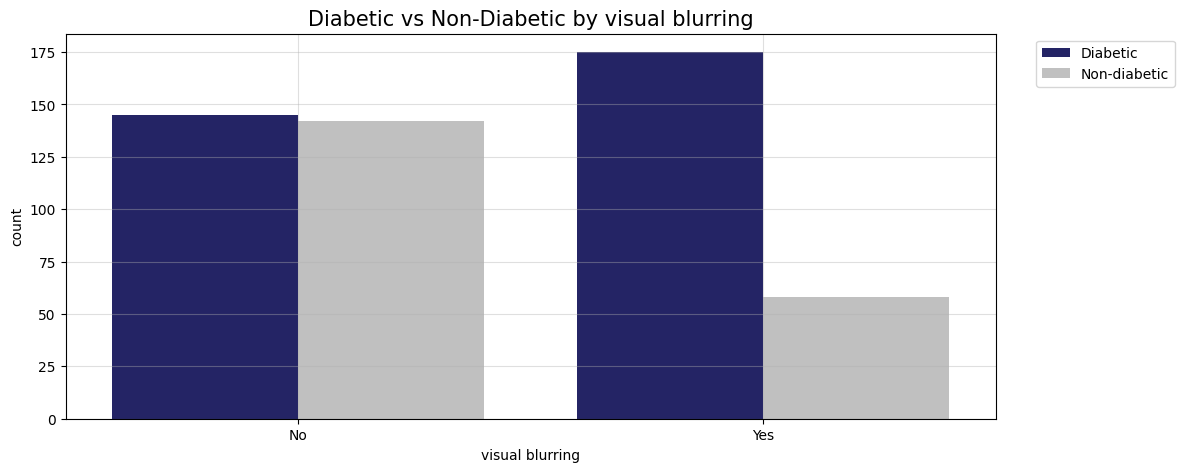

Observed value:


,Diabetic,Non-diabetic
visual blurring,,
No,142,145
Yes,58,175


Expected frequency:


,Diabetic,Non-diabetic
visual blurring,,
No,110.384615,176.615385
Yes,89.615385,143.384615


Test statistics:  31.8085
Test p-value:  0.0
Reject null hypothesis. There is a statistically significant association between visual blurring and the likelihood of diabetes in the analyzed data.


In [21]:
chi2test('visual blurring')

#### Question 9 | Is there a statistically significant association between the presence of itching and the likelihood of diabetes?

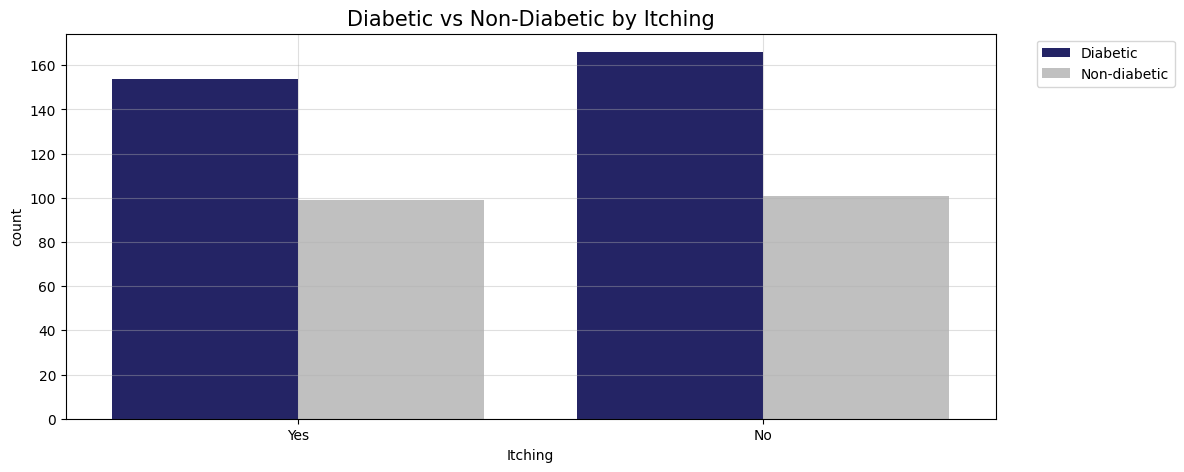

Observed value:


,Diabetic,Non-diabetic
Itching,,
No,101,166
Yes,99,154


Expected frequency:


,Diabetic,Non-diabetic
Itching,,
No,102.692308,164.307692
Yes,97.307692,155.692308


Test statistics:  0.0462
Test p-value:  0.8297
Failed to reject null hypothesis. Lack of evidence to conclude a statistically significant association between Itching and the likelihood of diabetes in the analyzed data.


In [22]:
chi2test('Itching')

#### Question 10 | Is there a statistically significant association between the presence of irritability and the likelihood of diabetes?

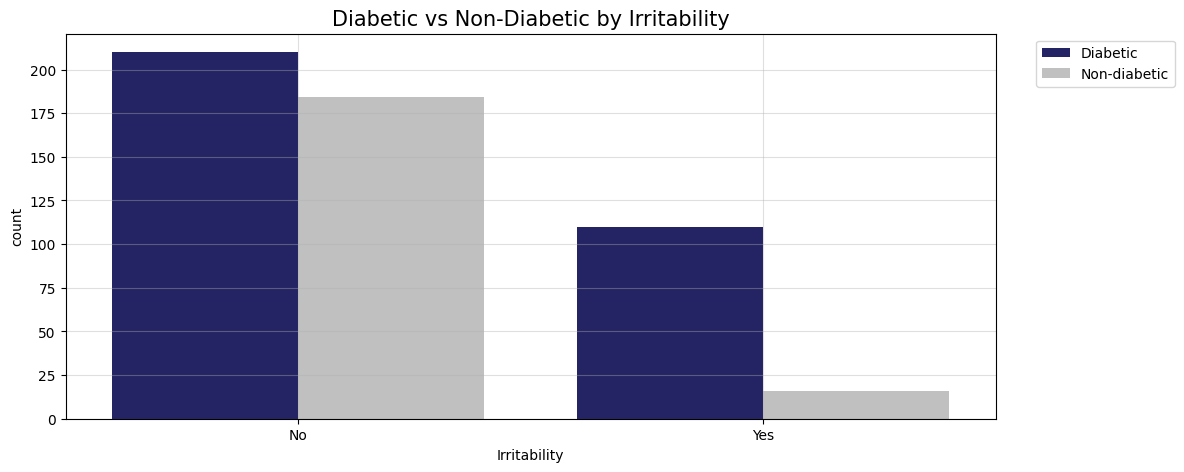

Observed value:


,Diabetic,Non-diabetic
Irritability,,
No,184,210
Yes,16,110


Expected frequency:


,Diabetic,Non-diabetic
Irritability,,
No,151.538462,242.461538
Yes,48.461538,77.538462


Test statistics:  45.2083
Test p-value:  0.0
Reject null hypothesis. There is a statistically significant association between Irritability and the likelihood of diabetes in the analyzed data.


In [23]:
chi2test('Irritability')

#### Question 11 | Does the presence of delayed healing exhibit a statistically significant association with the likelihood of diabetes?

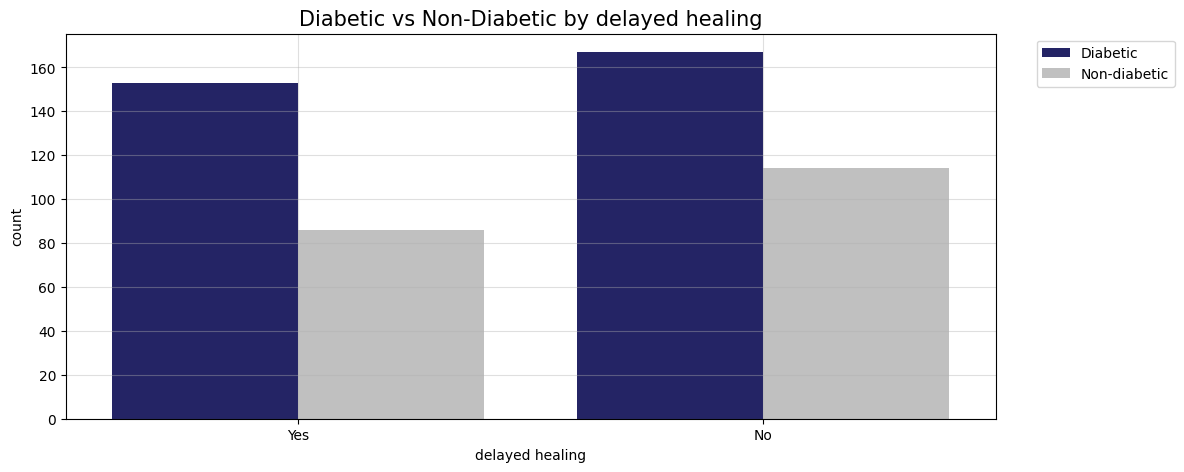

Observed value:


,Diabetic,Non-diabetic
delayed healing,,
No,114,167
Yes,86,153


Expected frequency:


,Diabetic,Non-diabetic
delayed healing,,
No,108.076923,172.923077
Yes,91.923077,147.076923


Test statistics:  0.9621
Test p-value:  0.3267
Failed to reject null hypothesis. Lack of evidence to conclude a statistically significant association between delayed healing and the likelihood of diabetes in the analyzed data.


In [24]:
chi2test('delayed healing')

#### Question 12 | Does the presence of partial paresis exhibit a statistically significant association with the likelihood of diabetes?

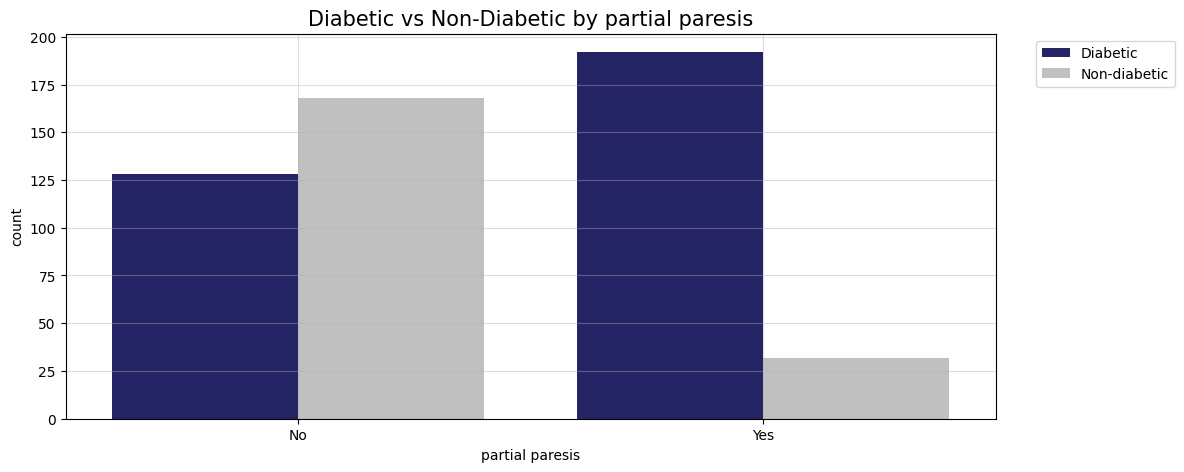

Observed value:


,Diabetic,Non-diabetic
partial paresis,,
No,168,128
Yes,32,192


Expected frequency:


,Diabetic,Non-diabetic
partial paresis,,
No,113.846154,182.153846
Yes,86.153846,137.846154


Test statistics:  95.3876
Test p-value:  0.0
Reject null hypothesis. There is a statistically significant association between partial paresis and the likelihood of diabetes in the analyzed data.


In [25]:
chi2test('partial paresis')

#### Question 13 | Does the presence of muscle stiffness exhibit a statistically significant association with the likelihood of diabetes?

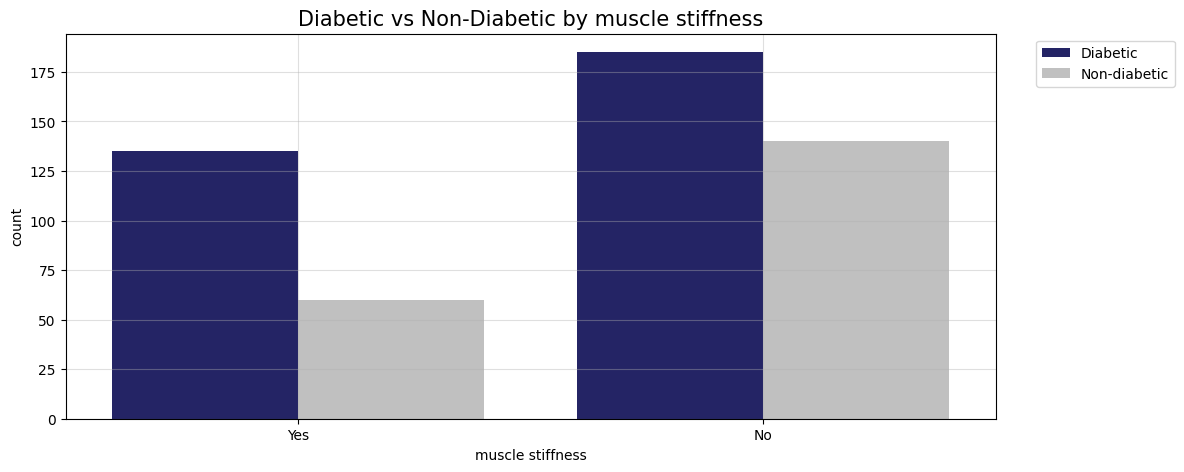

Observed value:


,Diabetic,Non-diabetic
muscle stiffness,,
No,140,185
Yes,60,135


Expected frequency:


,Diabetic,Non-diabetic
muscle stiffness,,
No,125.0,200.0
Yes,75.0,120.0


Test statistics:  7.2887
Test p-value:  0.0069
Reject null hypothesis. There is a statistically significant association between muscle stiffness and the likelihood of diabetes in the analyzed data.


In [26]:
chi2test('muscle stiffness')

#### Question 14 | Does the presence of alopecia exhibit a statistically significant association with the likelihood of diabetes?

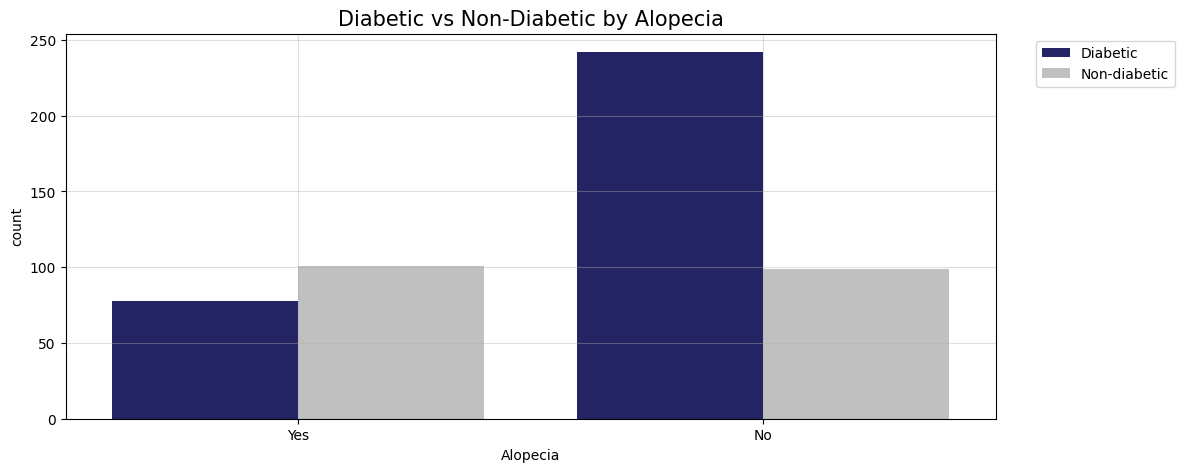

Observed value:


,Diabetic,Non-diabetic
Alopecia,,
No,99,242
Yes,101,78


Expected frequency:


,Diabetic,Non-diabetic
Alopecia,,
No,131.153846,209.846154
Yes,68.846154,110.153846


Test statistics:  36.0641
Test p-value:  0.0
Reject null hypothesis. There is a statistically significant association between Alopecia and the likelihood of diabetes in the analyzed data.


In [27]:
chi2test('Alopecia')

#### Question 15 | Does obesity exhibit a statistically significant association with the likelihood of diabetes?

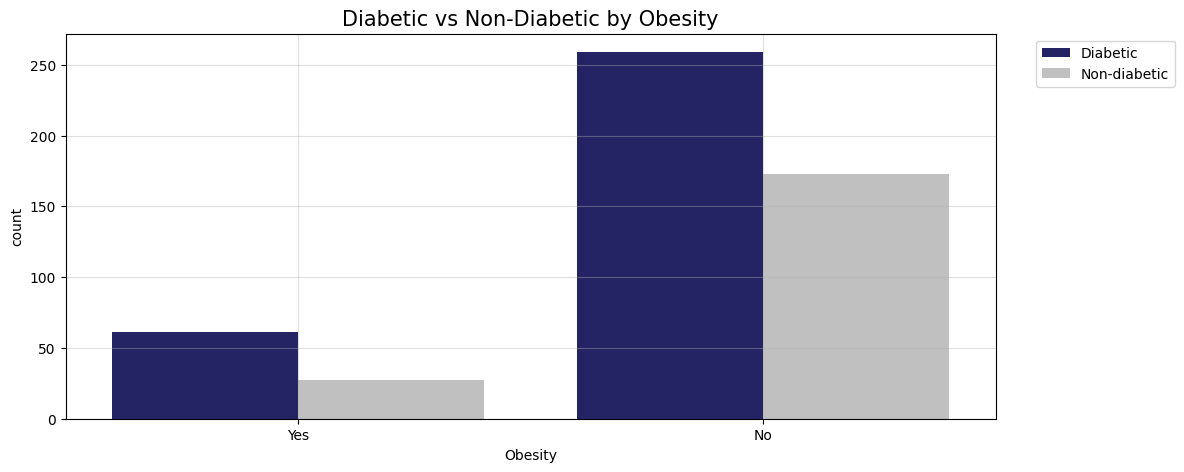

Observed value:


,Diabetic,Non-diabetic
Obesity,,
No,173,259
Yes,27,61


Expected frequency:


,Diabetic,Non-diabetic
Obesity,,
No,166.153846,265.846154
Yes,33.846154,54.153846


Test statistics:  2.3275
Test p-value:  0.1271
Failed to reject null hypothesis. Lack of evidence to conclude a statistically significant association between Obesity and the likelihood of diabetes in the analyzed data.


In [28]:
chi2test('Obesity')

#### Question 16 | Is there a statistically significant association between age and the likelihood of diabetes?

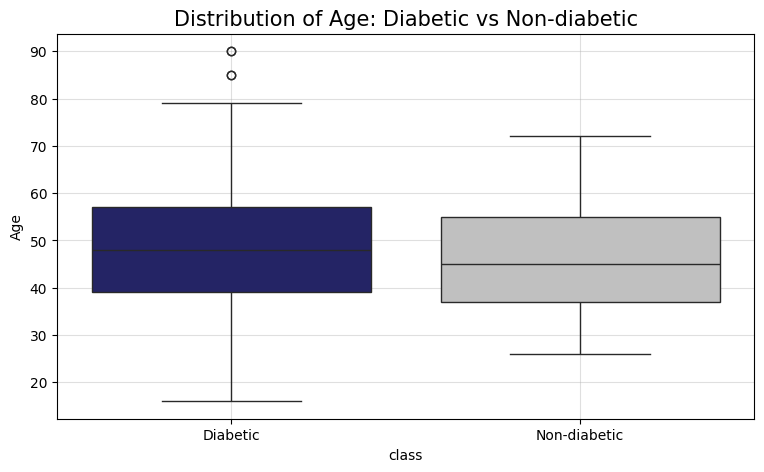

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
Negative,200.0,46.360000,12.080983,26.0,37.0,45.0,55.0,72.0
Positive,320.0,49.071875,12.097481,16.0,39.0,48.0,57.0,90.0


Test statistic:  36166.0
Test p-value:  0.0124
Reject null hypothesis. There is a statistically significant difference in age between diabetic and non-diabetic groups.


In [29]:
from scipy.stats import mannwhitneyu
# visualization 
plt.figure(figsize=(9,5))
sns.boxplot(data=data, x=data['class'], y=data['Age'], hue=data['class'], palette=colors)
plt.title('Distribution of Age: Diabetic vs Non-diabetic', fontsize=15)
plt.xticks([0,1], ['Diabetic','Non-diabetic'])
plt.grid(alpha=0.4)
plt.show()

# display summary statistic
outcome = data.groupby('class')
diabetic = outcome.get_group('Positive')
non_diabetic = outcome.get_group('Negative')
display(outcome['Age'].describe())

# perform Mann-Whitney U test to compare the age between diabetic and non-diabetic groups
res = mannwhitneyu(diabetic['Age'],non_diabetic['Age'])
test_stat = round(res[0], 4)
pvalue = round(res[1], 4)

print('Test statistic: ', test_stat)
print('Test p-value: ', pvalue)

alpha = 0.05
if pvalue < alpha:
    print('Reject null hypothesis. There is a statistically significant difference in age between diabetic and non-diabetic groups.')
else:
    print('Failed to reject null hypothesis. Lack of evidence to conclude a statistically significant difference in age between diabetic and non-diabetic groups.')